<a href="https://colab.research.google.com/github/Thuliofj/Desafio_01_Festival_Musica/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Celula - 1: Importação de bibliotecas

In [ ]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Celula - 2: Carregar Dados

In [ ]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "atracoes"   # ex.: "livros"
NOME_TABELA_FATO = "ingressos_vendidos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
atracoes -> 10100 linhas
ingressos_vendidos -> 55000 linhas


### celula - 3 : Olhar a tabela dimensão

In [ ]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10100 linhas e 7 colunas (variáveis)


,atracao_id,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,Banda Moura,sertanejo,Festival Illo 2025,2025-01-23,eletronico,20:45
1,2,Coletivo Casa Grande,rap,Festival Nobis 2026,2026-04-20,secundario,13:45
2,3,Banda da Rosa,eletronica,Festival Voluptate 2023,2023-05-23,secundario,12:00
3,4,Banda Farias,rap,Festival Iusto 2026,2026-10-11,principal,16:00
4,5,Rodrigues,reggae,Festival Aperiam 2023,2023-04-06,eletronico,12:30


### Celula - 4 : Conhecendo a tabela fato


In [ ]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix


### Pergunta que eu quero responder:
Valores mais altos são pagos via qual forma de pagamento, existem outliers em alguma das formas de pagamento? Algum outlier é mais expressivo em alguma das forma de pagamento?


# Localizar algo dentro de index

In [ ]:
registro = df_dimensao.loc[df_dimensao["atracao_id"] == 679 ]
print(registro)

     atracao_id nome_artista genero_musical          edicao_festival  \
678         679    DJ Duarte          forró  Festival Accusamus 2022   

    dia_apresentacao       palco horario_inicio  
678       2022-10-07  eletronico          18:30  


### Celula 5 - Tipos das colunas


In [ ]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   venda_id         55000 non-null  int64  
 1   atracao_id       55000 non-null  int64  
 2   tipo_ingresso    55000 non-null  object 
 3   canal_venda      55000 non-null  object 
 4   data_hora_venda  55000 non-null  object 
 5   valor            55000 non-null  float64
 6   forma_pagamento  55000 non-null  object 
dtypes: float64(1), int64(2), object(4)
memory usage: 2.9+ MB


### Celula 6 - Valores Ausentes


In [ ]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
venda_id           0
atracao_id         0
tipo_ingresso      0
canal_venda        0
data_hora_venda    0
valor              0
forma_pagamento    0
dtype: int64


### Celula 7 - Linhas Duplicadas


In [ ]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Celula 8 - Chave estrangeira

In [ ]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "atracao_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "atracao_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


### Célula 09 · Checar a coluna numérica

In [ ]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "valor"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


### Celula 10 - Medidas estatisticas

In [ ]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,469.54
Mediana,290.00
Moda,202.98
Desvio padrão,455.12
Variância,207135.74
Mínimo,80.55
Máximo,2975.31
Amplitude,2894.76


Média - mediana: 179.54


- **A média de valor é R$ 469,54.** Para o festival, isso representa o ticket médio gasto por ingresso vendido em toda a base.

- **A mediana de valor é R$ 290,00.** Ela mostra que metade dos ingressos custou até R$ 290,00 e fica R$ 179,54 abaixo da média porque poucos ingressos muito caros puxam a média para cima.

- **O desvio padrão de valor é R$ 455,12.** Essa variação quase igual ao valor da própria média mostra que os preços dos ingressos são bastante espalhados entre entradas comuns de pista e setores especiais.

- **Decisão final:** Como a média (R$ 469,54) está bem distante da mediana (R$ 290,00) e o desvio padrão é alto (R$ 455,12), o festival deve usar a mediana como referência do ingresso típico e comparar os meios de pagamento separadamente antes de definir ações comerciais.

###Celula 11 - Juntar a Fato e dimensão

In [ ]:
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))
print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))


Linhas da fato: 55000 | depois da junção: 55000


In [ ]:
df_completo.head()

,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento,faixa_valor,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix,Até R$ 300,Farias,rock,Festival Fuga 2022,2022-11-13,secundario,19:30
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito,R$ 300 a R$ 1.000,As Silveira,eletronica,Festival Neque 2026,2026-04-27,principal,22:00
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix,Até R$ 300,As Vieira,sertanejo,Festival Fuga 2022,2022-11-12,principal,15:45
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito,R$ 300 a R$ 1.000,Coletivo Costela,sertanejo,Festival Eveniet 2021,2021-04-17,principal,16:00
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix,Até R$ 300,Santos,funk,Festival Quo 2020,2020-02-13,principal,12:30


### Célula 12 · Comparar grupos por uma coluna da fato

In [ ]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "forma_pagamento"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
forma_pagamento,,,,
cartao_credito,27767,471.45,291.73,455.00
cartao_debito,8228,470.71,291.55,455.38
pix,16252,469.42,287.72,459.52
boleto,2753,447.48,284.45,428.40


**Leitura por forma_pagamento**

- O grupo `cartao_credito` tem a maior média (R$ 471,45) e a mediana confirma essa liderança (R$ 291,73), acompanhado bem de perto pelo `cartao_debito` (média de R$ 470,71 e mediana de R$ 291,55).
- O grupo `pix` tem o maior desvio padrão (R$ 459,52), mostrando valores ligeiramente mais espalhados, embora todas as modalidades tenham média muito maior que a mediana e desvio padrão acima de R$ 428,00 (sinal de outliers de alto valor em todos os grupos).
- Como as médias entre `cartao_credito` (R$ 471,45), `cartao_debito` (R$ 470,71) e `pix` (R$ 469,42) são muito parecidas, a forma de pagamento sozinha não altera o preço médio do ingresso, mas o `count` mostra que o cartão de crédito concentra o maior volume de compras (27.767 vendas).

In [ ]:
COLUNA_GRUPO = "genero_musical"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
genero_musical,,,,
forró,3198,482.97,296.58,453.54
reggae,2172,480.63,286.68,473.22
rock,6914,475.49,296.29,457.11
funk,7297,471.63,290.74,452.54
rap,6133,468.80,288.55,455.04
pop,8300,466.93,288.42,456.12
sertanejo,8063,465.43,287.58,454.16
eletronica,8000,464.93,287.61,455.64
mpb,4923,463.99,290.67,448.14


**Leitura por genero_musical**

- O grupo `forró` tem a maior média (R$ 482,97) e a mediana confirma essa liderança (R$ 296,58), seguido de perto pelo `rock` na mediana (R$ 296,29).
- O grupo `reggae` tem o maior desvio padrão (R$ 473,22), indicando que os valores pagos nesse gênero são os mais espalhados entre ingressos simples e camarotes.
- Como os grupos têm médias muito parecidas (variando em uma faixa estreita de R$ 463,99 na MPB a R$ 482,97 no forró), o gênero musical não é o fator que define o preço do ingresso vendido.

In [ ]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -347.47 a 1104.52
Outliers: 4653 de 55000 valores
Maiores valores: [2975.31, 2973.81, 2957.95, 2944.94, 2943.81]
Menores valores: [80.55, 81.14, 81.34, 81.77, 81.92]


In [ ]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,469.54,357.40
Mediana,290.00,273.09
Desvio padrão,455.12,238.74


**Leitura e decisão registrada**

- A regra do IQR marcou 4.653 valores como candidatos a outlier (de 55.000 registros), correspondendo aos ingressos acima de R$ 1.104,52 (o limite inferior calculado foi de -R$ 347,47, sem registros abaixo dele, pois o menor ingresso custa R$ 80,55). Sem esses valores extremos, a média cai de R$ 469,54 para R$ 357,40 e o desvio padrão cai de R$ 455,12 para R$ 238,74, enquanto a mediana muda pouco (de R$ 290,00 para R$ 273,09).
- **Decisão:** Manter os outliers na base de dados, porque representam compras reais e legítimas de ingressos de setores mais caros (como VIP e camarote), essenciais para analisar os pagamentos de valores mais altos.
- **Valores ausentes:** Nenhuma remoção ou preenchimento foi realizado, pois a conferência inicial confirmou 0 valores ausentes na coluna `valor` e nas demais colunas da tabela fato.

Gemini - Ajudou com a reformulação da frase

In [ ]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.36


A assimetria é positiva (2,36), o que indica uma cauda longa para a direita com poucos valores altos puxando a média acima da mediana.

In [ ]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     139.1380
0.25     197.0275
0.50     290.0050
0.75     560.0225
0.90    1028.7440
Name: valor, dtype: float64


In [ ]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

0.10     139.1380
0.25     197.0275
0.50     290.0050
0.75     560.0225
0.90    1028.7440
Name: valor, dtype: float64


,count
valor,
"(77.655, 659.502]",43778
"(659.502, 1238.454]",7740
"(1238.454, 1817.406]",1717
"(1817.406, 2396.358]",1331
"(2396.358, 2975.31]",434


**Leitura da distribuição**

- A assimetria é positiva (2,36), o que indica uma cauda longa para a direita com poucos valores altos puxando a média acima da mediana.
- Pelos percentis, 75% dos registros ficam até R$ 560,02 e 90% dos registros ficam até R$ 1.028,74.
- Na primeira faixa de valor (entre R$ 77,66 e R$ 659,50) estão concentrados 43.778 registros, enquanto apenas 434 registros ficam na faixa mais alta (entre R$ 2.396,36 e R$ 2.975,31).
- Em palavras: a maioria dos valores fica entre R$ 197,03 e R$ 560,02, e poucos passam de R$ 1.104,52.

## Recomendação

**Pergunta de negócio:** Valores mais altos são pagos via qual forma de pagamento, existem outliers em alguma das formas de pagamento? Algum outlier é mais expressivo em alguma das forma de pagamento?

**Evidência 1:** Na comparação por `forma_pagamento`, o `cartao_credito` lidera em volume (27.767 vendas), média (R$ 471,45) e mediana (R$ 291,73), mas as médias e medianas de `cartao_debito` (R$ 470,71 e R$ 291,55) e `pix` (R$ 469,42 e R$ 287,72) são quase idênticas, desta forma valores mais altos não tem um pagamento escolhido para apenas uma forma de pagamento

**Evidência 2:** A regra do IQR identificou 4.653 outliers acima de R$ 1.104,52 (chegando até R$ 2.975,31), que elevam a média geral de R$ 357,40 para R$ 469,54; como todas as formas de pagamento têm média bem acima da mediana e desvio padrão alto (de R$ 428,40 no boleto a R$ 459,52 no Pix), existem valores extremos em todas as modalidades, com maior concentração no cartão de crédito (2.370 vendas acima de R$ 1.104,52).

**Evidência 3:** Estatisticamente, nenhuma modalidade sofre distorção exclusiva, pois todas têm entre 8,38% e 8,73% de outliers dentro de seus grupos e tetos próximos (de R$ 2.784,95 no boleto a R$ 2.975,31 no débito); porém, do ponto de vista de negócio, os outliers do `boleto` (239 vendas acima de R$ 1.035,08, chegando a R$ 2.784,95) são os mais expressivos por ocorrerem em uma modalidade de baixo volume (2.753 vendas) e menor mediana (R$ 284,45), representando quase 10 vezes o gasto típico desse meio de pagamento.

**Recomendação em uma frase:** Como o valor médio pago no cartão e no Pix é praticamente igual, mas o cartão de crédito concentra o maior volume de compras (27.767 vendas no total e 2.370 entre os ingressos mais caros), o festival deve priorizar estabilidade no checkout e opções de parcelamento no cartão de crédito para sustentar as vendas de maior valor, mantendo o Pix ativo sem necessidade de descontos exclusivos.

**Limites da análise:** Todos os 4.653 outliers acima de R$ 1.104,52 foram mantidos por representarem vendas reais de setores especiais, e a base não possui valores ausentes.

Gemini - Ajudou com a reformulação da frase

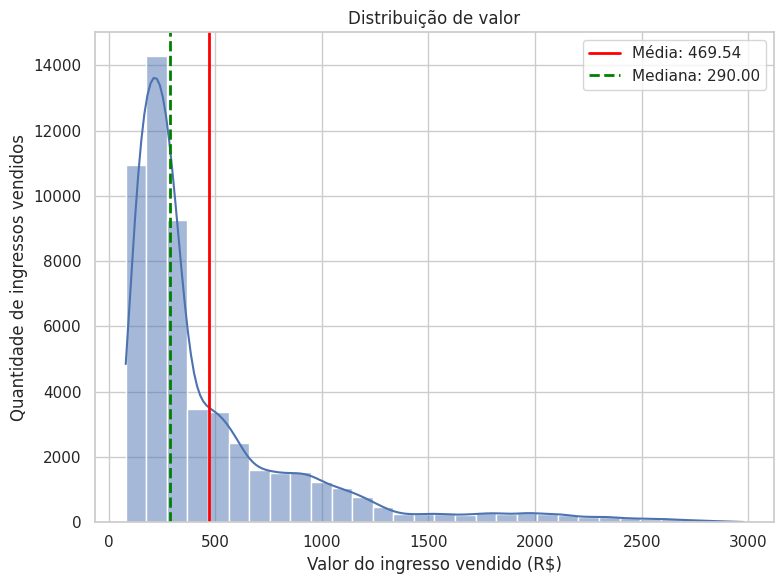

In [ ]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Valor do ingresso vendido (R$)")
plt.ylabel("Quantidade de ingressos vendidos")
plt.legend()
plt.tight_layout()
plt.show()

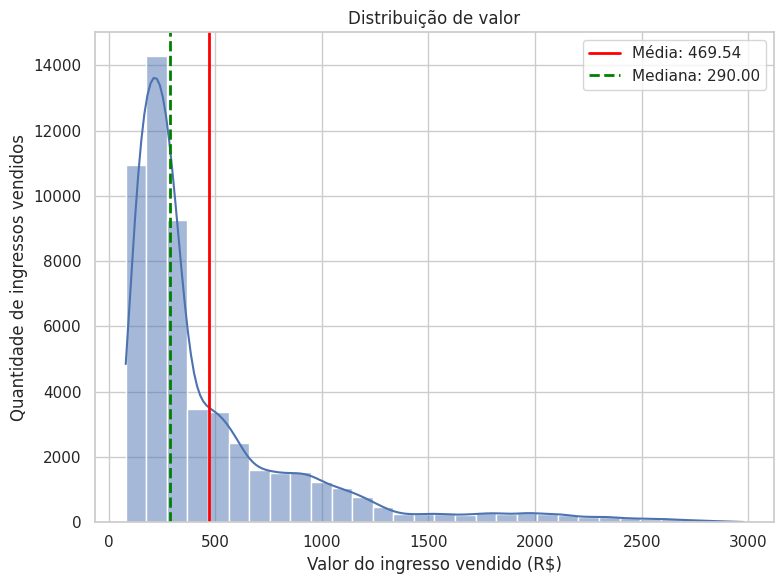

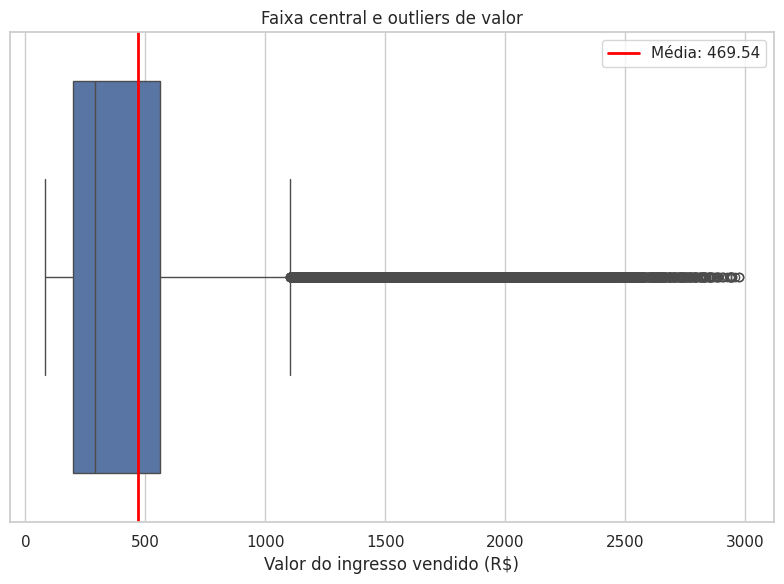

In [ ]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Valor do ingresso vendido (R$)")
plt.ylabel("Quantidade de ingressos vendidos")
plt.legend()
plt.tight_layout()
plt.show()

# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Valor do ingresso vendido (R$)")
plt.legend()
plt.tight_layout()
plt.show()

**Leitura dos gráficos**

- O histograma e o boxplot mostram uma forte assimetria à direita, onde a maioria das vendas se concentra abaixo da mediana de R$ 290,00, enquanto os 4.653 ingressos acima de R$ 1.104,52 formam uma longa cauda de outliers que puxa a média para R$ 469,54.
- Na comparação entre formas de pagamento (boxplot por grupo, gráfico de colunas dos ingressos acima de R$ 1.104,52 e boxplot específico do boleto), observa-se que todas as modalidades apresentam outliers de alto valor (incluindo 239 boletos acima de R$ 1.035,08, que chegam a R$ 2.784,95), mas o cartão de crédito concentra mais da metade das compras na faixa mais cara (2.370 vendas).

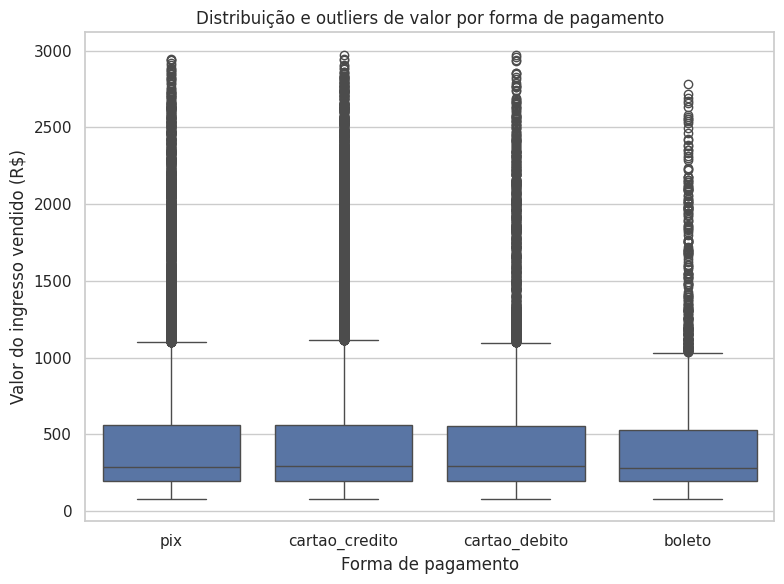

In [ ]:
# Boxplot por grupo: compara a faixa central (25% a 75%), a mediana e os outliers de cada forma de pagamento.
sns.boxplot(data=df_completo, x="forma_pagamento", y="valor")
plt.title("Distribuição e outliers de valor por forma de pagamento")
plt.xlabel("Forma de pagamento")
plt.ylabel("Valor do ingresso vendido (R$)")
plt.tight_layout()
plt.show()

**Leitura dos gráficos**
         
    - O boxplot comparativo mostra que as caixas centrais (entre cerca de R$ 197 e R$ 560) e as medianas (linhas horizontais dentro das caixas, próximas de R$ 290) são praticamente iguais nas quatro formas de pagamento, enquanto os pontos acima de R$ 1.100 confirmam que existem outliers de alto valor em todas as modalidades, chegando perto de R$ 3.000 no cartão e no Pix.

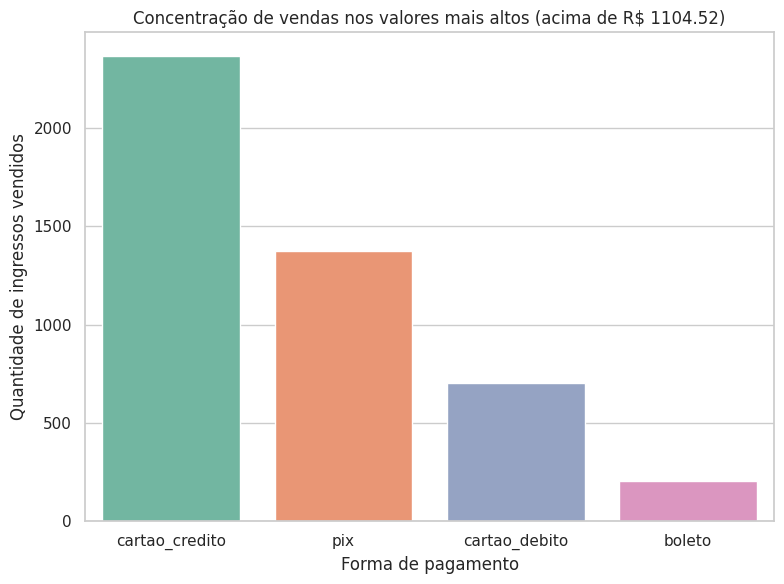

In [ ]:
# Filtra apenas os valores mais altos (acima do limite_superior calculado na Célula 14)
mais_caros = df_completo[df_completo["valor"] > limite_superior]

# Gráfico de colunas com paleta de cores alterada
sns.countplot(
    data=mais_caros,
    x="forma_pagamento",
    order=mais_caros["forma_pagamento"].value_counts().index,
    palette="Set2"
)
plt.title(f"Concentração de vendas nos valores mais altos (acima de R$ {limite_superior:.2f})")
plt.xlabel("Forma de pagamento")
plt.ylabel("Quantidade de ingressos vendidos")
plt.tight_layout()
plt.show()

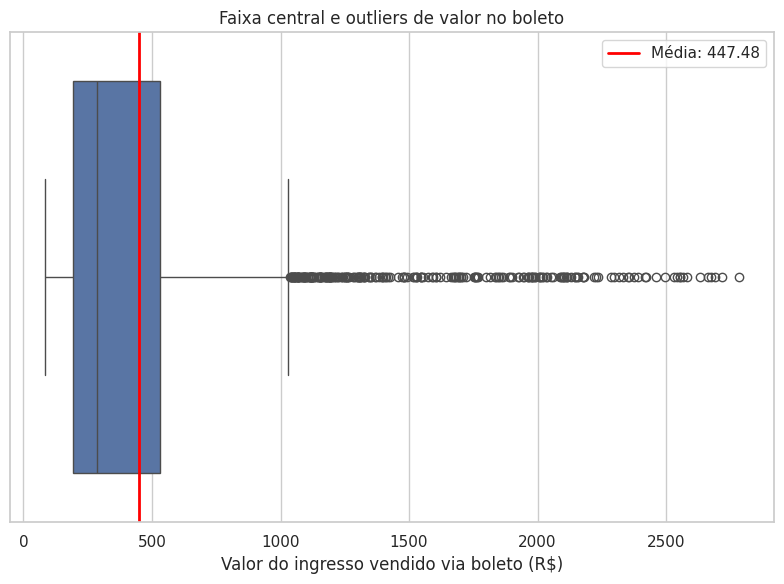

In [ ]:
# Filtra apenas os valores pagos via boleto
boletos = df_completo[df_completo["forma_pagamento"] == "boleto"]["valor"]

# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=boletos.dropna())
plt.axvline(boletos.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {boletos.mean():.2f}")
plt.title("Faixa central e outliers de valor no boleto")
plt.xlabel("Valor do ingresso vendido via boleto (R$)")
plt.legend()
plt.tight_layout()
plt.show()

O boxplot mostra que 75% das compras pagas via boleto ficam concentradas até R$ 530,39 (com mediana de R$ 284,45), mas os 239 pontos à direita da caixa (acima de R$ 1.035,08, chegando até R$ 2.784,95) puxam a média do boleto para R$ 447,48.